# 13 -- SrTiO$_3$ [001] STEM: ADF, HAADF, BF, ABF and iDPC from quantum circuits

Five STEM contrast modes from one simulation, computed with QuScope's quantum multislice and checked against abTEM on the same potential, probe, scan and detectors.

| mode | detector | what it shows in SrTiO$_3$ |
|---|---|---|
| HAADF | annulus 70-120 mrad | Z-contrast: Sr columns brightest, Ti+O weaker, pure O columns barely above background |
| ADF | annulus 30-70 mrad | same ordering as HAADF, with the O columns faintly visible |
| BF | disc 0-22 mrad | phase contrast: heavy columns dark on a bright background; depends on thickness and defocus |
| ABF | annulus 11-22 mrad | heavy columns dark, O columns as weak dark dots |
| iDPC | centre of mass of the BF disc, integrated | specimen phase: all columns bright, the weaker O columns included |

**How the quantum part works.** For every probe position the focused probe is amplitude-encoded on $2\log_2N$ qubits, and each slice applies a diagonal phase gate $e^{i\sigma V_j}$ followed by Fresnel propagation $\mathrm{QFT}^\dagger\,e^{-i\pi\lambda\Delta z k^2}\,\mathrm{QFT}$. The QFTs run as Qiskit circuits; the exit wave is read out and integrated over the detectors.

**Requires** QuScope with the STEM fixes in [QuScope PR #28](https://github.com/QuScope/QuScope/pull/28) (iDPC integration, scan registration, detector normalisation) and abTEM >= 1.0.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
from ase import Atoms
import abtem

from quscope.quantum_ctem.quantum_stem import STEMDetectors
from quscope.quantum_ctem.quantum_stem_multislice import run_stem_multislice, build_probe_circuit, fresnel_propagator_phase
from quscope.quantum_ctem.quantum_ctem_circuit import relativistic_wavelength, interaction_constant

abtem.config.set({"local_diagnostics.progress_bar": False})

VOLTAGE = 200e3
A_LAT = 3.905                  # SrTiO3 lattice constant [A]
N = 64                         # grid points per side -> 12 qubits
N_CELLS_Z = 4                  # thickness: 4 unit cells = 15.6 A
ALPHA = 22.0                   # probe semi-angle [mrad], aberration-free
SCAN = 32                      # probe positions per axis (SCAN*SCAN circuits per mode set)

# detector angles [mrad]
DET = STEMDetectors(haadf_inner=70, haadf_outer=120, adf_inner=30, adf_outer=70,
                    abf_inner=11, abf_outer=22, bf_outer=22)
LAM = relativistic_wavelength(VOLTAGE)
print(f"{N}x{N} grid = {2*int(np.log2(N))} qubits, pixel {A_LAT/N:.4f} A, "
      f"Nyquist angle {1e3*LAM/(2*A_LAT/N):.0f} mrad, {SCAN*SCAN} probe positions")

64x64 grid = 12 qubits, pixel 0.0610 A, Nyquist angle 206 mrad, 1024 probe positions


## 1. Structure and potential

Cubic perovskite, Sr at the corner, Ti at the body centre, O at the face centres. Looking down [001] there are three kinds of column: **Sr**, **Ti + O** and two **pure O** columns per cell. The cell is $1\times1$ with periodic boundaries; the potential comes from abTEM (Kirkland parametrisation, infinite projection), one slice per half cell (SrO and TiO$_2$ layers), and is passed unchanged to both codes.

tasks:   0%|          | 0/2 [00:00<?, ?it/s]

potential array: (8, 64, 64)  slice thickness 1.9525 A


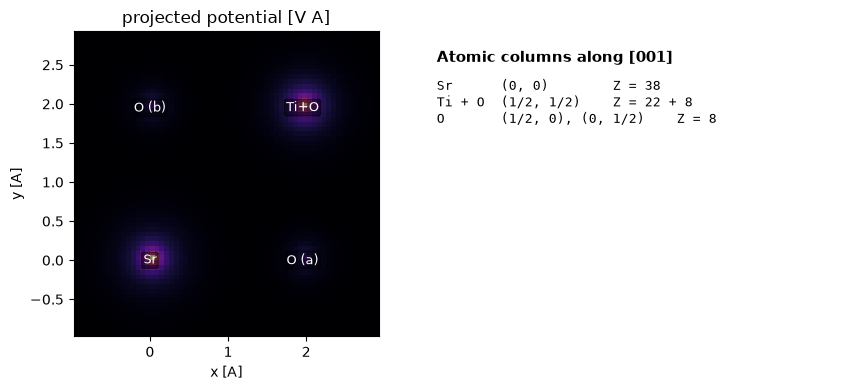

In [2]:
sto = Atoms("SrTiO3",
            scaled_positions=[(0, 0, 0), (.5, .5, .5), (.5, .5, 0), (.5, 0, .5), (0, .5, .5)],
            cell=[A_LAT] * 3, pbc=True)
atoms = sto.repeat((1, 1, N_CELLS_Z))
potential = abtem.Potential(atoms, gpts=N, projection="infinite",
                            parametrization="kirkland", slice_thickness=A_LAT / 2)
V = potential.build().compute().array          # (slices, N, N), V*A
print("potential array:", V.shape, " slice thickness", A_LAT / 2, "A")

# projected columns for reference
cols = {"Sr": (0, 0), "Ti+O": (.5, .5), "O (a)": (.5, 0), "O (b)": (0, .5)}
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
shift = N // 4                                  # show the cell from -a/4 so no column sits on the border
ax[0].imshow(np.roll(V.sum(0), (shift, shift), (0, 1)).T, origin="lower", cmap="magma",
             extent=[-A_LAT / 4, 3 * A_LAT / 4, -A_LAT / 4, 3 * A_LAT / 4])
for lab, (fx, fy) in cols.items():
    ax[0].annotate(lab, (fx * A_LAT, fy * A_LAT), color="w", ha="center", va="center", fontsize=9,
                   bbox=dict(boxstyle="round,pad=0.15", fc="k", alpha=.5))
ax[0].set_title("projected potential [V A]"); ax[0].set_xlabel("x [A]"); ax[0].set_ylabel("y [A]")
ax[1].axis("off")
ax[1].text(0, .9, "Atomic columns along [001]", fontsize=11, weight="bold")
ax[1].text(0, .7, "Sr      (0, 0)        Z = 38\nTi + O  (1/2, 1/2)    Z = 22 + 8\nO       (1/2, 0), (0, 1/2)    Z = 8", family="monospace", fontsize=9)
plt.tight_layout(); plt.show()

## 2. Quantum multislice STEM

One probe position is one circuit. The next cell prints the circuit for a single position (8 phase-grating gates and 7 QFT / propagator / inverse-QFT blocks), then scans the probe over the cell.

The 12-qubit statevector simulation costs about 0.1 to 0.3 s per probe position on a laptop, so the default 32 x 32 scan takes several minutes. Set `SCAN = 16` for a quick run.

In [3]:
sigma = interaction_constant(VOLTAGE, LAM)
gratings = [np.exp(1j * sigma * v).ravel() for v in V]
prop = fresnel_propagator_phase(N, A_LAT / N, LAM, A_LAT / 2)
qc = build_probe_circuit(2 * int(np.log2(N)), gratings, prop)
print(f"one probe position: {qc.num_qubits} qubits, {len(qc.data)} circuit blocks, "
      f"{dict(qc.count_ops())}")

one probe position: 12 qubits, 43 circuit blocks, {'diagonal': 15, 'qft': 14, 'qft_dg': 14}


In [4]:
t0 = time.time()
quantum = run_stem_multislice(V, pixel_size=A_LAT / N, voltage=VOLTAGE,
                              slice_thickness=A_LAT / 2, convergence_mrad=ALPHA,
                              cs_mm=0.0, detectors=DET, scan_step_px=N // SCAN)
t_quantum = time.time() - t0
print(f"{quantum['metrics']['approach']}\n{SCAN*SCAN} probe positions in {t_quantum:.0f} s "
      f"({t_quantum/SCAN**2:.2f} s per position)")

Quantum multislice STEM (8 slices, diagonal-as-array-multiply + QFT-via-circuit)
1024 probe positions in 298 s (0.29 s per position)


## 3. abTEM reference

Same potential, same probe (aberration-free, 22 mrad), same scan grid, same detectors. abTEM's iDPC is `DiffractionPatterns.integrated_center_of_mass()`, applied to the 0-22 mrad disc.

In [5]:
probe = abtem.Probe(energy=VOLTAGE, semiangle_cutoff=ALPHA, soft=False)
probe.grid.match(potential)
detectors = [abtem.AnnularDetector(0, 22), abtem.AnnularDetector(11, 22),
             abtem.AnnularDetector(30, 70), abtem.AnnularDetector(70, 120),
             abtem.PixelatedDetector(max_angle=22)]
scan = abtem.GridScan((0, 0), (A_LAT, A_LAT), gpts=SCAN, endpoint=False)

t0 = time.time()
bf, abf, adf, haadf, dp = [m.compute() for m in probe.scan(potential, scan=scan, detectors=detectors)]
reference = {"HAADF": haadf.array, "ADF": adf.array, "BF": bf.array, "ABF": abf.array,
             "iDPC": dp.integrated_center_of_mass().array}
print(f"abTEM: {time.time()-t0:.0f} s")

tasks:   0%|          | 0/4 [00:00<?, ?it/s]

tasks:   0%|          | 0/4 [00:00<?, ?it/s]

tasks:   0%|          | 0/4 [00:00<?, ?it/s]

tasks:   0%|          | 0/4 [00:00<?, ?it/s]

tasks:   0%|          | 0/4 [00:00<?, ?it/s]

abTEM: 4 s


## 4. The five images

Each image is tiled $3\times3$ unit cells for display (the cell is periodic) and interpolated for clarity. Top row: quantum circuits. Bottom row: abTEM.

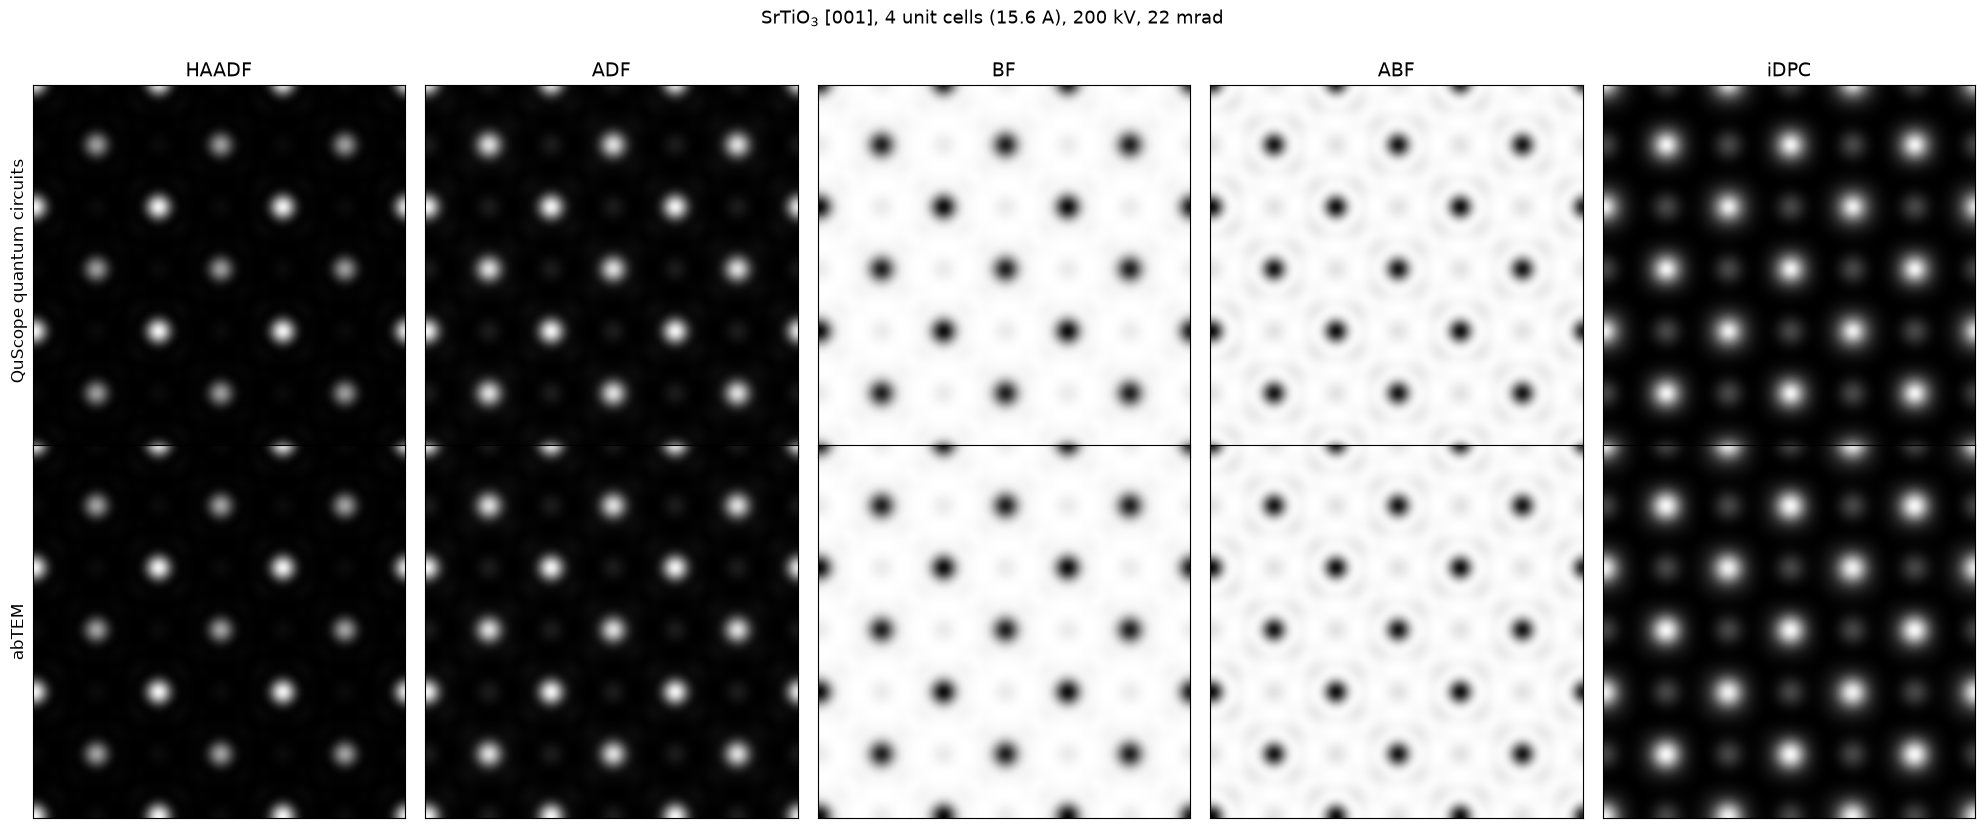

In [6]:
MODES = ["HAADF", "ADF", "BF", "ABF", "iDPC"]
CMAPS = {"HAADF": "gray", "ADF": "gray", "BF": "gray", "ABF": "gray", "iDPC": "gray"}

def tiled(img):
    return np.tile(img, (3, 3)).T                   # x horizontal

fig, axes = plt.subplots(2, 5, figsize=(20, 8.4))
ext = [0, 3 * A_LAT, 0, 3 * A_LAT]
for j, m in enumerate(MODES):
    for i, (src, label) in enumerate([(quantum, "QuScope quantum circuits"), (reference, "abTEM")]):
        ax = axes[i, j]
        ax.imshow(tiled(src[m]), origin="lower", extent=ext, cmap=CMAPS[m], interpolation="bicubic")
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(m, fontsize=14)
        if j == 0: ax.set_ylabel(label, fontsize=12)
fig.suptitle(f"SrTiO$_3$ [001], {N_CELLS_Z} unit cells ({N_CELLS_Z*A_LAT:.1f} A), {VOLTAGE/1e3:.0f} kV, "
             f"{ALPHA:.0f} mrad", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

## 5. Quantitative comparison

The two codes normalise differently only for iDPC (QuScope returns the phase in radians, abTEM an arbitrary scale), so each mode is compared after a least-squares scale and offset. The last columns give the intensity at the Sr, Ti+O and pure-O columns relative to the image mean.

In [7]:
def column_values(img):
    idx = lambda f: int(round(f * SCAN)) % SCAN
    return {lab: img[idx(fx), idx(fy)] for lab, (fx, fy) in cols.items()}

print(f"{'mode':6s} {'corr':>8s} {'NRMSE':>8s}   " + "   ".join(f"{c:>13s}" for c in cols))
results = {}
for m in MODES:
    q, a = quantum[m].ravel(), reference[m].ravel()
    corr = np.corrcoef(q, a)[0, 1]
    s, o = np.polyfit(a, q, 1)
    nrmse = np.sqrt(np.mean((q - (s * a + o)) ** 2)) / (q.max() - q.min())
    results[m] = (corr, nrmse)
    rel = lambda img: {k: v / img.mean() if abs(img.mean()) > 1e-12 else v for k, v in column_values(img).items()}
    if m == "iDPC":      # zero-mean images: report min-max normalised value
        norm = lambda img: (img - img.min()) / (img.max() - img.min())
        cq, ca = column_values(norm(quantum[m])), column_values(norm(reference[m]))
    else:
        cq, ca = rel(quantum[m]), rel(reference[m])
    print(f"{m:6s} {corr:8.5f} {nrmse:8.4f}   " +
          "   ".join(f"{cq[c]:6.2f}/{ca[c]:<6.2f}" for c in cols))
print("\ncolumn entries: QuScope / abTEM  (relative to image mean; iDPC min-max normalised)")
assert all(c > 0.99 for c, _ in results.values())

mode       corr    NRMSE              Sr            Ti+O           O (a)           O (b)
HAADF   0.99985   0.0022    20.35/19.90     12.91/13.08      0.89/0.91       0.89/0.91  
ADF     1.00000   0.0003    12.43/12.44     11.25/11.22      1.52/1.52       1.52/1.52  
BF      1.00000   0.0001     0.47/0.47       0.52/0.52       0.99/0.99       0.99/0.99  
ABF     1.00000   0.0000     0.37/0.37       0.39/0.39       0.97/0.97       0.97/0.97  
iDPC    0.99745   0.0125     0.98/0.97       1.00/1.00       0.28/0.28       0.28/0.28  

column entries: QuScope / abTEM  (relative to image mean; iDPC min-max normalised)


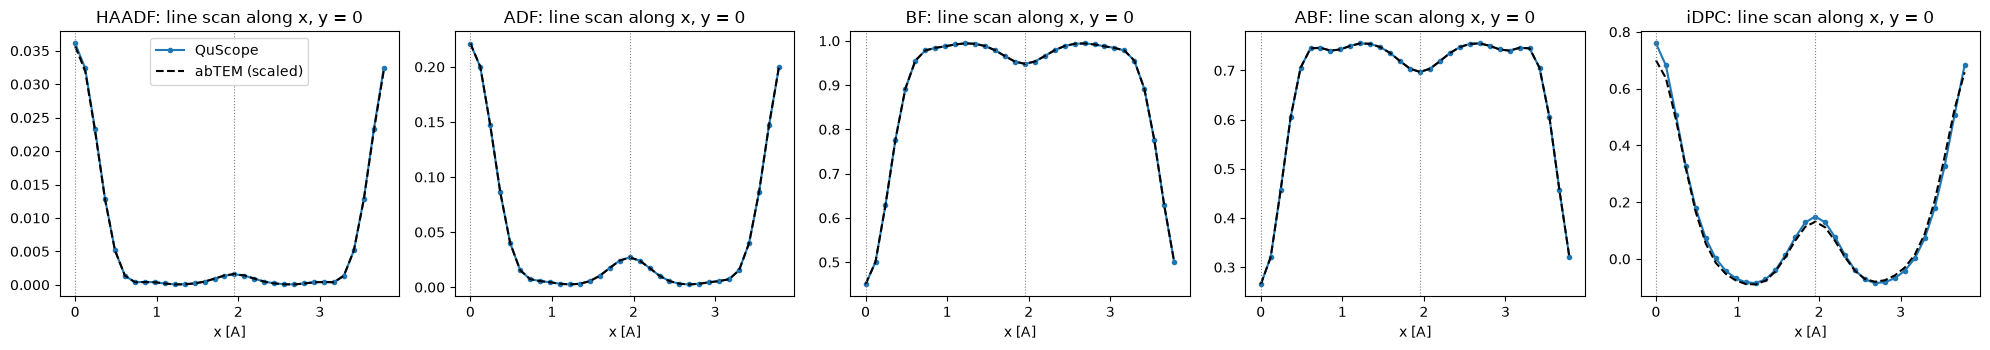

In [8]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.6))
for j, m in enumerate(MODES):
    q, a = quantum[m], reference[m]
    s, o = np.polyfit(a.ravel(), q.ravel(), 1)
    ax[j].plot(np.linspace(0, A_LAT, SCAN, endpoint=False), q[:, 0], "o-", ms=3, label="QuScope")
    ax[j].plot(np.linspace(0, A_LAT, SCAN, endpoint=False), s * a[:, 0] + o, "k--", label="abTEM (scaled)")
    ax[j].set_title(f"{m}: line scan along x, y = 0"); ax[j].set_xlabel("x [A]")
    for f, lab in [(0, "Sr"), (.5, "O")]:
        ax[j].axvline(f * A_LAT, color="grey", ls=":", lw=.8)
ax[0].legend(); plt.tight_layout(); plt.show()

## Notes

* **Agreement.** The quantum multislice reproduces abTEM for all five modes: correlations of 1.0000 (ADF, BF, ABF), 0.9998 (HAADF) and 0.997 (iDPC), and the same column ordering. The small HAADF and iDPC residuals are probably due to abTEM band-limiting the multislice at 2/3 of Nyquist, which QuScope's propagator does not do; this was not isolated here.
* **Contrast.** The line scans cross a Sr column (x = 0) and an O column (x = a/2): in BF and ABF the O column is a shallow dip (about 4 to 7 % below the background) next to the deep heavy-column minima.
* **Sampling.** $1\times1$ periodic cell: the probe tails wrap around and interfere with their neighbours. A larger cell lowers this artefact but each doubling of the field quadruples the amplitudes (two more qubits).
* **Not included.** Thermal diffuse scattering. Real HAADF and ADF intensities are dominated by it; frozen-phonon averaging is planned for the next release (see `v0.3`).
* **Cost.** Per probe position the circuit has $O(n^2)$ QFT gates per slice on $n=2\log_2N$ qubits; the classical statevector simulation used here grows as $O(N^2)$ per gate.